# Экономия на масштабе, спрос и срок до заезда

**TL;DR.** Крупный хозяин может быть дешевле перед заездом благодаря меньшим издержкам и дороже заранее благодаря менее чувствительному к цене спросу. Ценность ожидания `V(L)` одинакова для обоих типов. Модель ниже показывает, когда сочетание этих предположений даёт смену знака. Это теоретический пример: параметры не оценены по Airbnb, а механизм не установлен нашей OLS.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from helpers.host_portfolio_economic_model import build
theory_examples, theory_method = build()
def theory_figure(name):
    display(Image(filename=str(Path('figures') / f'host_portfolio_model_{name}.png')))


## 1. Что выбирает хозяин

Рассматриваем одну свободную ночь одного объекта и одного потенциального гостя, который обращается сейчас. Размер портфеля `N` задан; хозяин не выбирает число объектов в этой задаче. Он нейтрален к риску и выбирает цену `p`, чтобы максимизировать ожидаемую чистую прибыль.

Сравниваем два типа: `N=1` и `N=20`. У них различаются переменные издержки обслуживания занятой ночи и чувствительность текущего спроса к цене. Альтернатива ожидания задана одинаково. Все денежные величины — в фунтах; `L` — число дней до заезда. Один объект и одна ночь — упрощение: совместное управление всеми квартирами, длина бронирования и ответы конкурентов здесь не моделируются.

Если текущий гость согласился, прибыль равна `p−c(N)`. Если отказался, хозяин сохраняет ночь для будущей возможности с ожидаемой чистой прибылью `V(L)`. Простой даёт ноль. Постоянные расходы, не зависящие от этого решения, опущены.

## 2. Три предпосылки

### Издержки: экономия на масштабе

Больший портфель может позволять дешевле организовать уборку, стирку и обслуживание. Записываем убывающие издержки на занятую ночь:

$$c(N)=50-k\ln N,\qquad k=\frac{15}{\ln20}\approx5{,}007.$$

Поэтому `c(1)=£50`, `c(20)=£35`. Функцию используем только для `1≤N≤20`. Экономия от следующего объекта постепенно уменьшается. Здесь важны переменные затраты на обслуживание, а не одно лишь распределение фиксированных расходов между квартирами.

### Спрос: разная чувствительность к цене

Вероятность бронирования текущим гостем:

$$q_N(p)=\left(\frac{p_0}{p}\right)^{\varepsilon_N},\qquad p\ge p_0,\quad p_0=40,\quad\varepsilon_N>1.$$

Для цены ниже `p₀` вероятность равна единице: такая цена хуже `p₀`, поскольку снижает выручку без роста вероятности продажи. Поэтому достаточно выбирать `p≥p₀`.

Чем выше `ε`, тем сильнее спрос реагирует на процентное изменение цены. Предполагаем `ε₁=3` и `ε₂₀=2`: у крупного хозяина спрос менее чувствителен. Это могло бы отражать узнаваемость или собственный канал продаж, но наше исследование этих преимуществ не измеряло. Само число объявлений их не доказывает. Для промежуточных портфелей функцию `ε(N)` не вводим: решаем задачу для двух типов.

### Общая ценность ожидания

$$V(L)=B(1-e^{-L/\tau}),\qquad B=40,\quad\tau=30\text{ дней}.$$

Сегодня `V(0)=0`; с увеличением срока ценность ожидания растёт всё медленнее и стремится к `£40`. Функция не зависит от `N`.

Одна возможная интерпретация: будущая возможность приносит одинаковую для обоих типов **чистую** выгоду `B`, а вероятность её появления за `L` дней равна `1−exp(−L/τ)`. Все будущие расходы в `B` уже учтены. Одинаковая чистая выгода не означает одинаковую валовую цену будущей заявки при разных издержках. Эту альтернативу задаём извне; не решаем целиком динамическую задачу всех будущих цен.

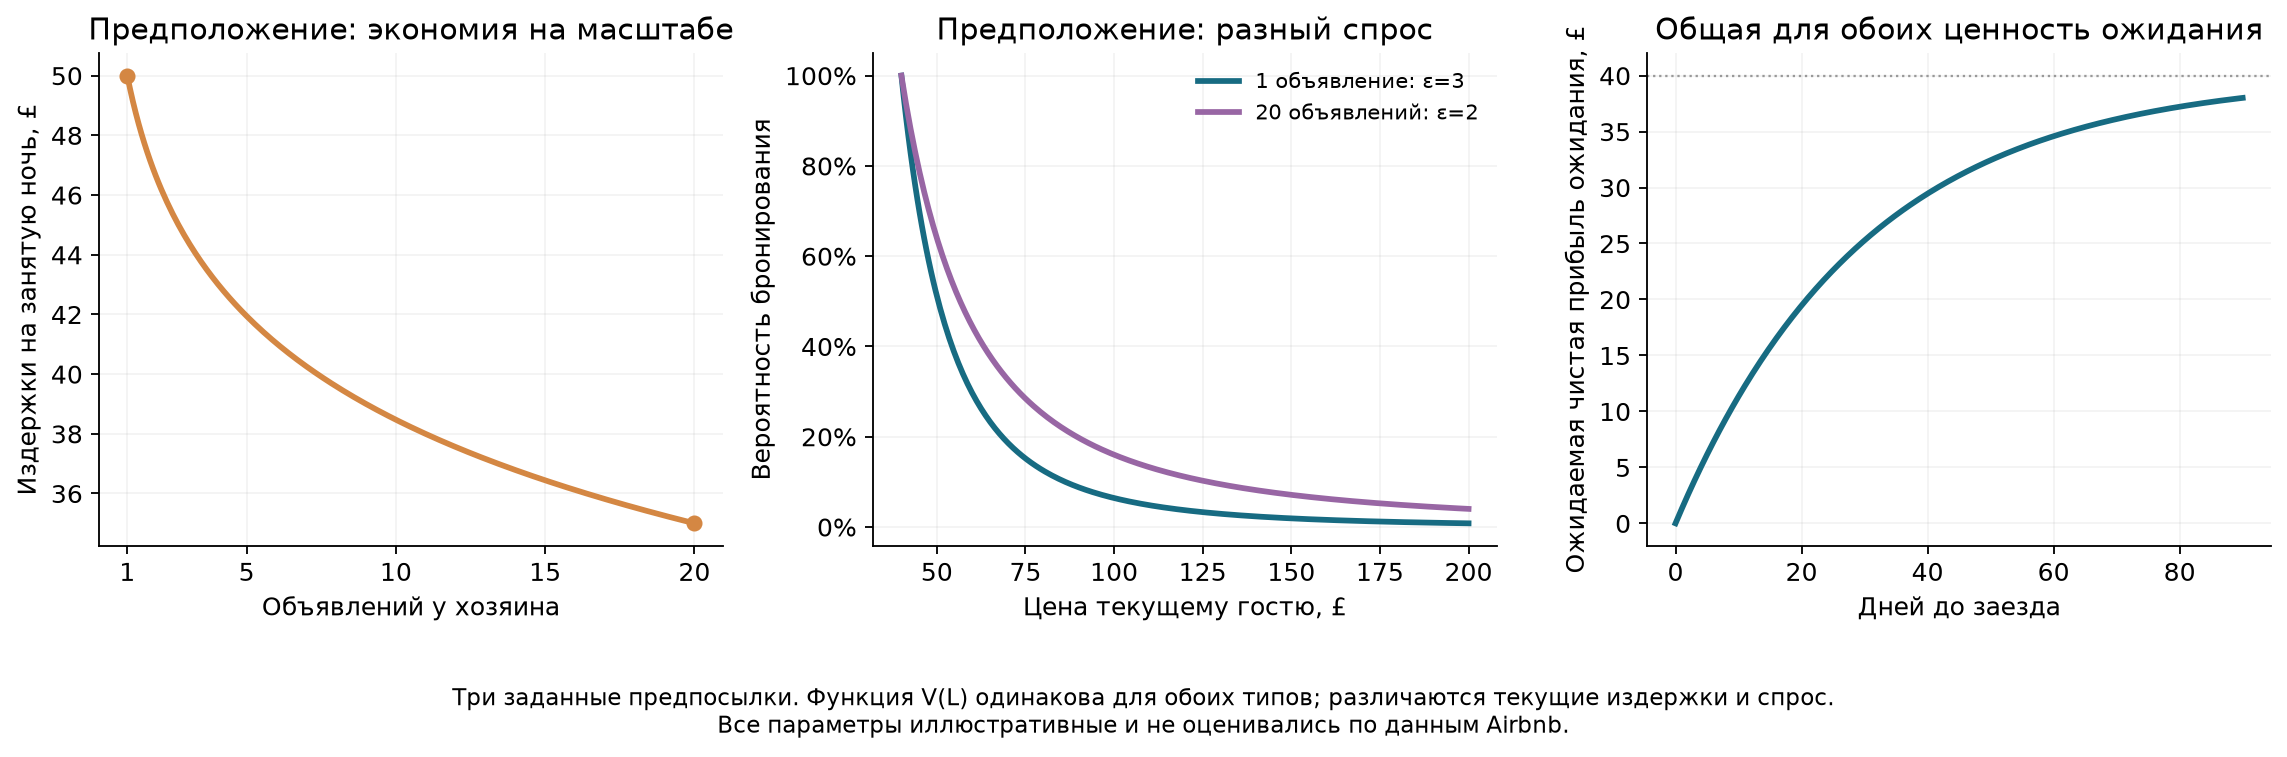

In [2]:
theory_figure('inputs')

## 3. Задача и решение

$$\max_{p\ge p_0}\;\pi_N(p,L)
=q_N(p)[p-c(N)]+[1-q_N(p)]V(L).$$

Обозначим `K=c(N)+V(L)`. Тогда:

$$\pi_N(p,L)=V(L)+p_0^{\varepsilon_N}p^{-\varepsilon_N}(p-K).$$

Производная по цене:

$$\frac{\partial\pi_N}{\partial p}
=p_0^{\varepsilon_N}p^{-\varepsilon_N-1}
\left[(1-\varepsilon_N)p+\varepsilon_N K\right].$$

Первый множитель положителен. Выражение в квадратных скобках положительно ниже `εK/(ε−1)` и отрицательно выше. Значит, это глобальный максимум, если он допустим; иначе максимум на нижней границе:

$$\boxed{p_N^*(L)=\max\left\{p_0,\frac{\varepsilon_N}{\varepsilon_N-1}[c(N)+V(L)]\right\}.}$$

Обозначим множитель `μ_N=ε_N/(ε_N−1)`. В нашем примере `μ₁=1,5`, `μ₂₀=2`, и оба оптимума при всех `L≥0` выше `p₀`. Граница поэтому не мешает сравнению.

`μ` — множитель к издержкам плюс упущенной возможности ожидания. Это не процент чистой прибыли и не оценённая доля рынка. При менее чувствительном спросе хозяин выбирает больший множитель.

## 4. Условие смены знака

Для малого хозяина обозначим величины индексом `м`, для крупного — `б`. Если оба оптимума внутренние:

$$\Delta p^*(L)=p_{б}^*(L)-p_{м}^*(L)
=\mu_{б}c_{б}-\mu_{м}c_{м}+(\mu_{б}-\mu_{м})V(L).$$

Пусть у крупного хозяина спрос менее чувствителен, то есть `μб>μм`. Чтобы он был дешевле сегодня, экономия должна быть достаточно большой: `μб cб<μм cм`. Тогда порог ценности ожидания:

$$V^*=\frac{\mu_{м}c_{м}-\mu_{б}c_{б}}{\mu_{б}-\mu_{м}}.$$

Конечный порог по времени существует только при `0<V*<B`. При выбранной функции ожидания:

$$L^*=-\tau\ln\left(1-\frac{V^*}{B}\right).$$

При `L<L*` крупный хозяин дешевле, при `L>L*` — дороже. Смена знака не гарантирована произвольными параметрами: если экономия слишком мала, крупный может быть дороже всегда; если будущая ценность слишком мала, он может остаться дешевле всегда.

## 5. Численный ответ

Подставляем параметры:

$$p_{м}^*(L)=1{,}5[50+40(1-e^{-L/30})]=135-60e^{-L/30},$$

$$p_{б}^*(L)=2[35+40(1-e^{-L/30})]=150-80e^{-L/30}.$$

Поэтому:

$$\boxed{\Delta p^*(L)=-5+0{,}5V(L)=15-20e^{-L/30}.}$$

Порог равен `V*=£10`, или `L*=30 ln(4/3)≈8,63 дня`. В этой точке обе цены равны `£90`. При большом сроке цены стремятся к `£135` и `£150`, а разница — к `£15`.

| До заезда | Общая V(L) | Цена малого | Цена крупного | Крупный минус малый |
|---|---:|---:|---:|---:|
| Сегодня | £0,00 | £75,00 | £70,00 | −£5,00 |
| 7 дней | £8,32 | £87,49 | £86,65 | −£0,84 |
| 14 дней | £14,92 | £97,37 | £99,83 | +£2,46 |
| 30 дней | £25,28 | £112,93 | £120,57 | +£7,64 |
| 60 дней | £34,59 | £126,88 | £139,17 | +£12,29 |


Справа на рисунке разница цен разбита на два слагаемых с наценкой малого хозяина как точкой отсчёта:

$$\Delta p^*=\underbrace{\mu_{м}(c_{б}-c_{м})}_{-22{,}50}
+\underbrace{(\mu_{б}-\mu_{м})(c_{б}+V)}_{17{,}50+0{,}5V}.$$

При таком способе разбора экономия тянет разницу вниз на `£22,50`. Более высокая наценка тянет её вверх на `£17,50` сегодня и всё сильнее с увеличением `V`. Это точное алгебраическое разложение выбранной модели с указанной точкой отсчёта. Оно не означает, что OLS разделила и оценила два канала.

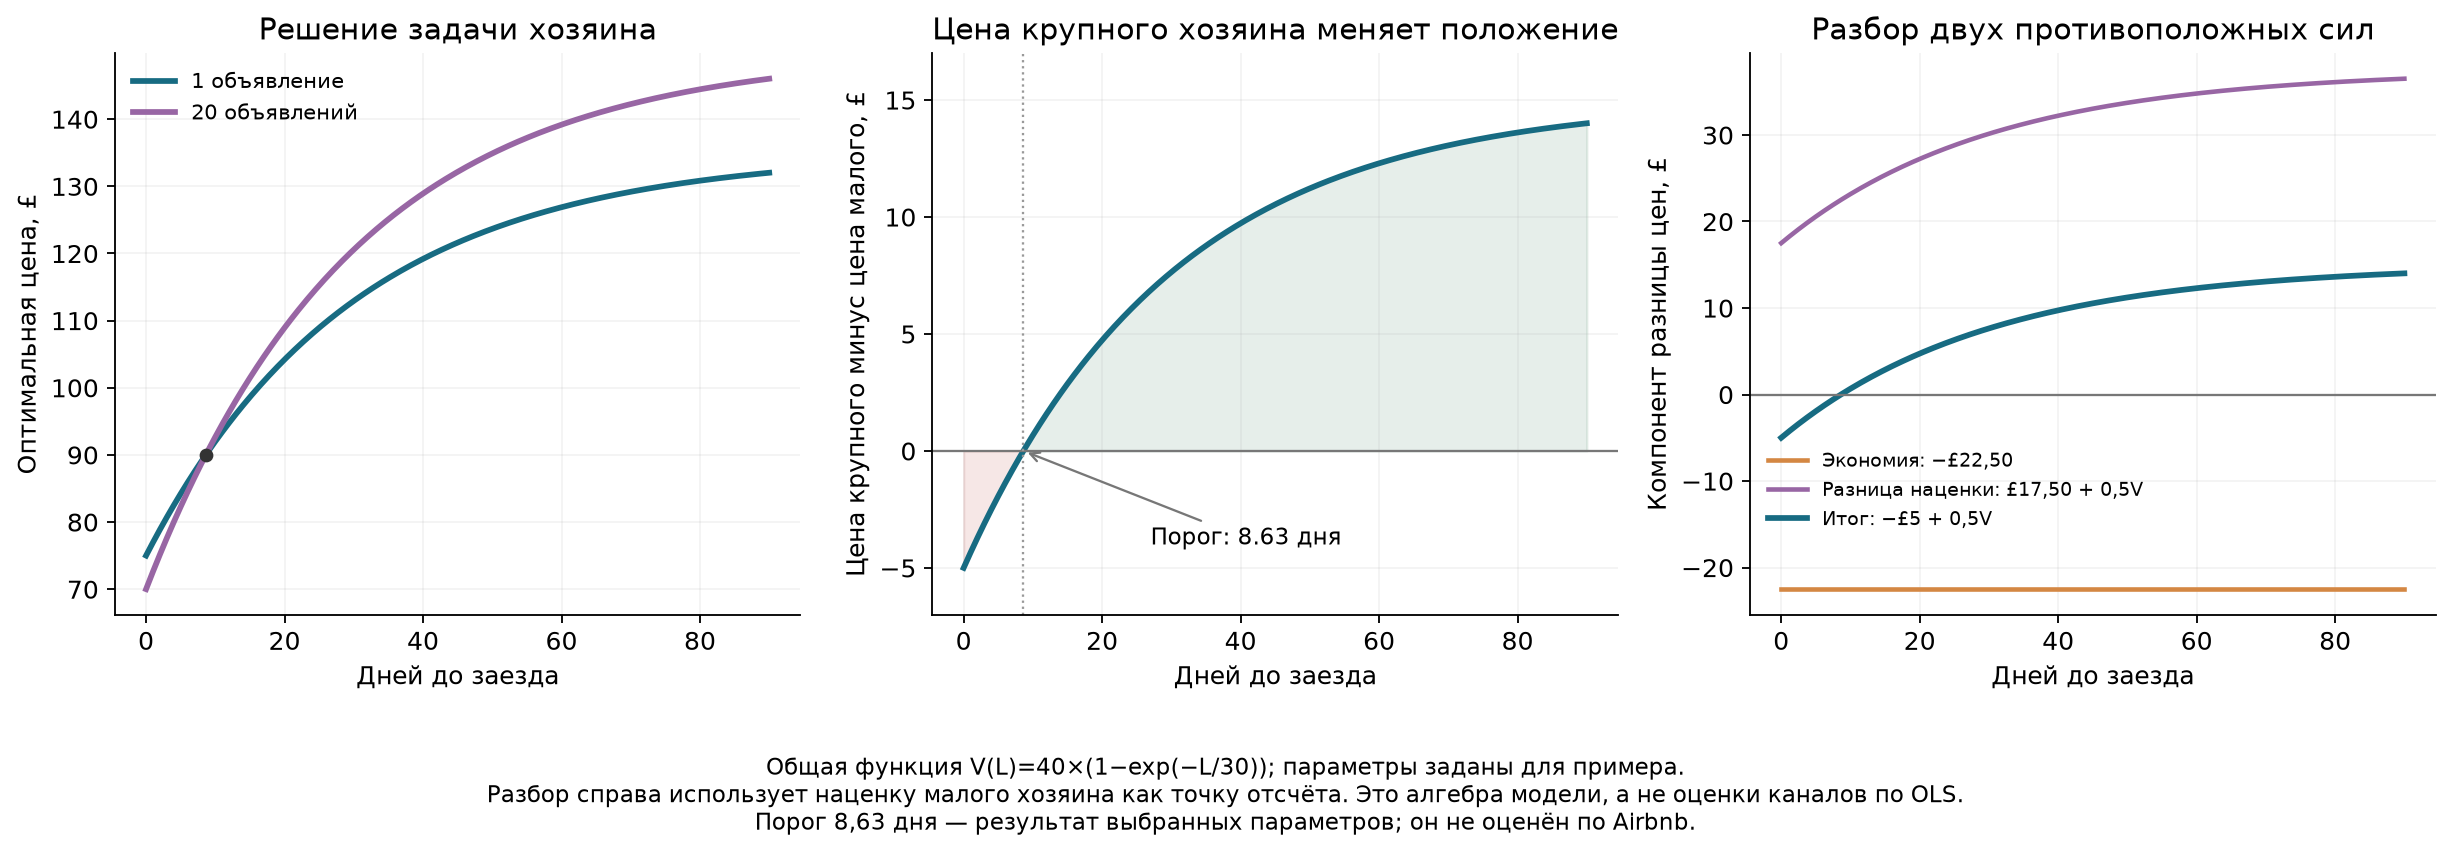

In [3]:
theory_figure('solution')

## 6. Что будет без одного из механизмов

Если оставить разные издержки, но сделать чувствительность спроса одинаковой (`ε=3`), разница равна `1,5×(35−50)=−£22,50` при любом сроке. Одна экономия на масштабе смены знака не даёт.

Если оставить разную чувствительность, но сделать издержки одинаковыми (`c=£50`), разница равна `0,5×(50+V)>0` при любом сроке. Одно преимущество в спросе также не даёт смены знака.

Если убрать оба различия, цены совпадут. Общая для всех `V(L)` сама по себе не создаёт разницы между одинаковыми типами.

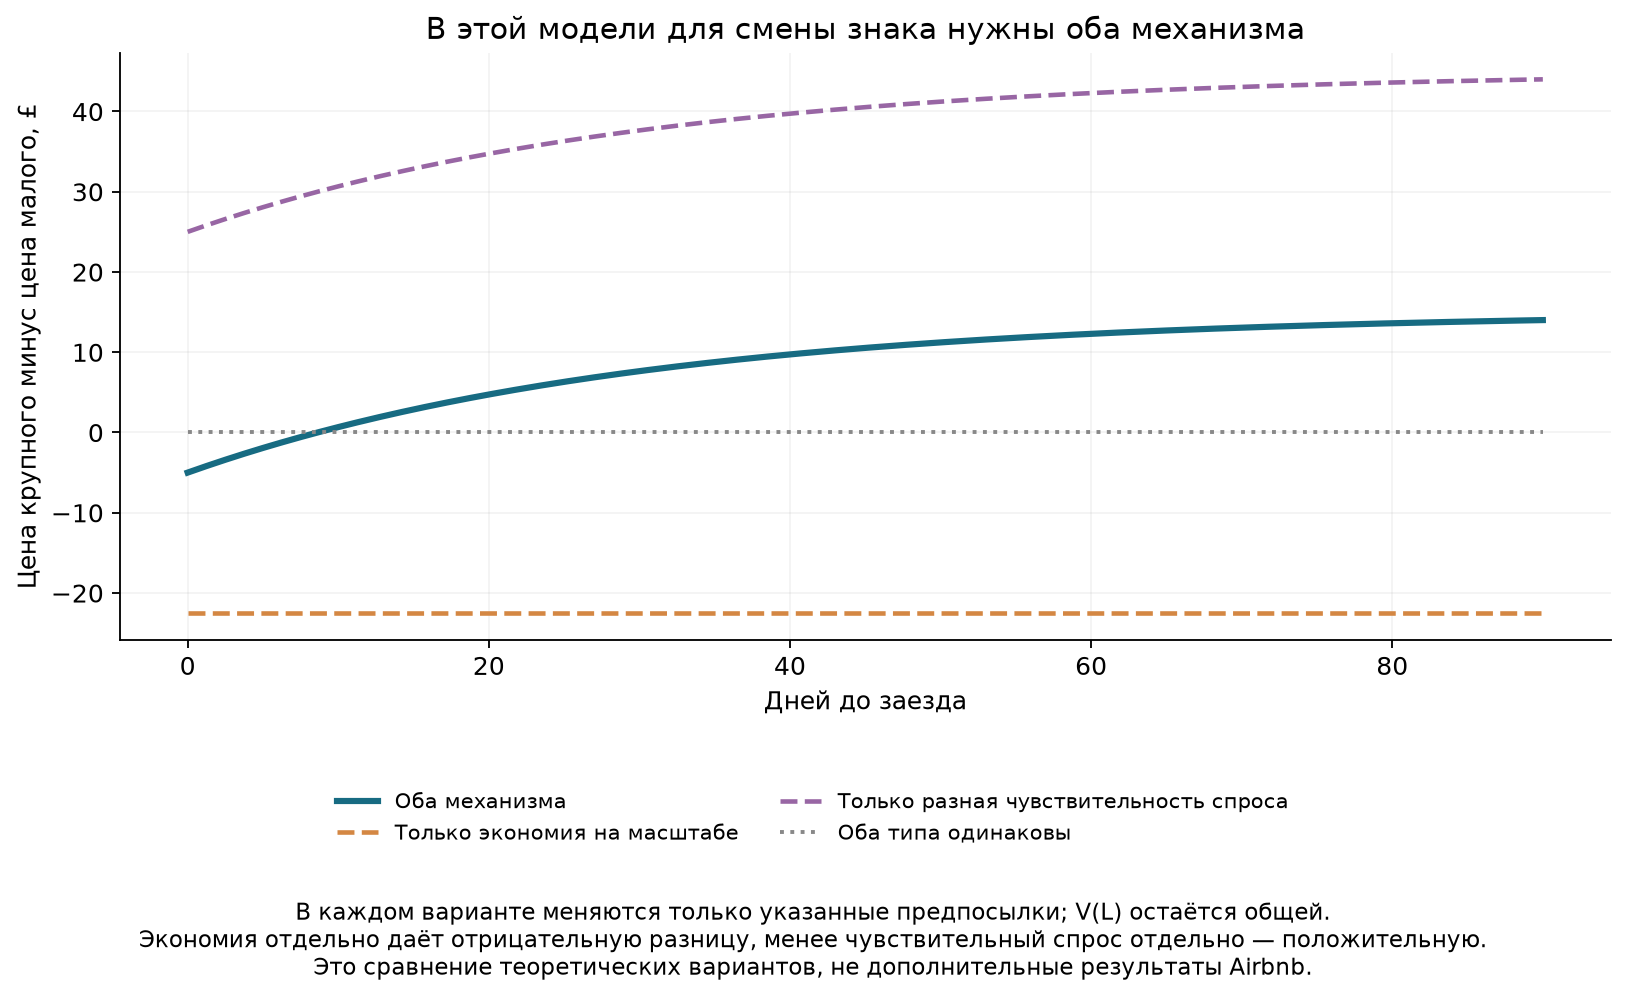

In [4]:
theory_figure('scenarios')

## 7. Что это объясняет в проекте

Модель даёт возможное объяснение найденной связи: при близком заезде может преобладать экономия издержек, а заранее — преимущество в наценке. Для этого `V` не обязана зависеть от размера портфеля.

Наши ICE и OLS не измеряли ни переменные издержки, ни чувствительность спроса, ни ценность ожидания. Поэтому этот рассказ не установлен данными, а параметры и порог 8,63 дня не являются оценками Airbnb. Сходная смена знака может возникать по другим причинам. Число объявлений также не доказывает рыночную власть.

Модель предсказывает, что цена одного типа объекта растёт со сроком до заезда. В проекте напрямую проверялась другая связь: как различается связь портфеля с ценой между сроками, с остальными контролями. Совпадение этого различия не означает, что все предсказания модели уже подтверждены. Для разделения механизмов нужны наблюдения за ценами и бронированиями во времени, затратами и реакцией спроса.

## 8. Как воспроизвести

Исполняемый ноутбук: [host_portfolio_economic_model.ipynb](host_portfolio_economic_model.ipynb). Код: [helpers/host_portfolio_economic_model.py](helpers/host_portfolio_economic_model.py).

Из корня репозитория в окружении проекта:

```bash
python helpers/host_portfolio_economic_model.py
```

Скрипт создаёт три рисунка в PNG и SVG, таблицу цен, примеры, сравнение четырёх вариантов и файл параметров `results/host_portfolio_model_method.json`. На 18 сочетаниях типа хозяина и срока аналитическое решение сверено с численной максимизацией ожидаемой прибыли. Отдельно проверены знаки производной вокруг максимума, совпадение аналитического и численного порогов, разложение разницы цен и отсутствие смены знака в двух упрощённых вариантах.

In [5]:
display(pd.Series(theory_method['checks'], name='Проверка решения'))

numeric_optimizations                  18
global_derivative_signs              True
analytical_numeric_crossing_match    True
decomposition_matches_prices         True
cost_only_no_sign_change             True
demand_only_no_sign_change           True
Name: Проверка решения, dtype: object